# NF binned template, all components, DC4 511 keV

Components 01–05 of Pascal's version 3.00 NF background model. Part 05 is the SAA component: activation that decays after the passages (the passages themselves are cut); its model counts equal the events of the SAA file after the cut (4,958,885).

Plan:
1. Model metadata of parts 01–05 (version, counts, livetime, input ranges).
2. Convergence of the 511 keV quadrature settings (validated on part 01) for parts 02–05.

In [1]:
%load_ext autoreload
%autoreload 2

## 1. Setup

In [2]:
import sys
from pathlib import Path
import torch                                   # first: torch after histpy/cosipy segfaults when building the flow
import numpy as np
import pandas as pd                            # comparison table of the four models
import yaml                                    # reads the template settings file
import healpy as hp                            # choose test pixels by sky position
import astropy.units as u
from histpy import Axes, Axis, HealpixAxis     # the binning given to the template class
import matplotlib.pyplot as plt
from cosipy.response.ml.NFModelIO import load_nf_model   # Pascal's reader for the v3 FITS model files

sys.path.insert(0, str(Path.cwd().parent.parent))     # project root, so `src` is importable
from src.nf_template import NFBinnedTemplate   # the template class (integrates the NF density per bin)
from src.plot_style import COLORS, set_global_style
set_global_style()                             # after the cosipy import

torch.set_num_threads(4)                       # fastest on your M5

%matplotlib inline


WARNING FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.



## 2. Model metadata

In [18]:
# Model files of the components used at 511 keV (05 = SAA component, activation after the passages)
PARTS = [1, 2, 3, 4, 5]
MODEL_PATHS = {p: Path(f"../../model/nfbackground_part-{p:02d}_v3-00.fits") for p in PARTS}

rows = []
for part, path in MODEL_PATHS.items():
    model_file = load_nf_model(path)                 # dict: "version", "rate_input", "density_input"
    rate_input = model_file["rate_input"]            # normalization: event count and livetime [s]
    density_input = model_file["density_input"]      # flow architecture and the input ranges it was trained on
    rows.append({
        "part": f"{part:02d}",
        "version": model_file["version"],
        "counts": int(rate_input["counts"]),
        "livetime_s": float(rate_input["livetime"]),
        "rate_Hz": rate_input["counts"] / rate_input["livetime"],   # R = counts / livetime, as ConstantBackgroundRate uses it
        # 511 keV window (509-513 keV) inside the Em range the flow was trained on
        "511_window_inside": density_input["menergy_cuts"][0] <= 509 and 513 <= density_input["menergy_cuts"][1],
        "bins": density_input["bins"],                               # flow architecture (should match across parts)
        "hidden_units": density_input["hidden_units"],
        "residual_blocks": density_input["residual_blocks"],
    })

metadata = pd.DataFrame(rows).set_index("part")
metadata

,version,counts,livetime_s,rate_Hz,511_window_inside,bins,hidden_units,residual_blocks
part,,,,,,,,
01,3.00,97554902,6579555.0,14.826976,True,384,256,5
02,3.00,27081364,6579555.0,4.115987,True,384,256,5
03,3.00,6176355,6579555.0,0.938719,True,384,256,5
04,3.00,25705670,6579555.0,3.906901,True,384,256,5
05,3.00,4958885,6579555.0,0.753681,True,384,256,5


## 3. 511 keV binning and FINAL settings

From `config/nf_template_settings.yaml` (case `dc4_511keV`), validated on part 01 in notebook 09.

In [4]:
# FINAL settings and binning for the DC4 511 keV imaging analysis (validated on part 01, notebook 09)
SETTINGS_PATH = Path("../../config/nf_template_settings.yaml")
with open(SETTINGS_PATH) as f:
    settings = yaml.safe_load(f)["dc4_511keV"]

binning = settings["binning"]
EM_EDGES_KEV  = np.array(binning["em_edges_kev"])                 # [509, 513] keV: 1 bin
PHI_EDGES_DEG = np.arange(0, 181, binning["phi_bin_deg"])         # 60 bins of 3 deg
NSIDE, SCHEME = binning["nside"], binning["scheme"]               # PsiChi: 3072 pixels

AXES = Axes([Axis(EM_EDGES_KEV * u.keV, label="Em"),
             Axis(PHI_EDGES_DEG * u.deg, label="Phi"),
             HealpixAxis(nside=NSIDE, scheme=SCHEME, label="PsiChi")])   # labels the class expects

FINAL = dict(settings["quadrature"])           # Em/Phi points, breaks and sky level k
K_FINAL = FINAL.pop("subpixel_level")          # k = 2; passed separately so we can vary it
print("FINAL:", FINAL, "| k =", K_FINAL)
print(AXES.labels, AXES.nbins)

FINAL: {'n_em_per_bin': 4, 'n_phi_per_bin': 4, 'em_breaks_kev': [511.0], 'phi_breaks_deg': [15.5, 16.0, 16.5, 17.0]} | k = 2
['Em' 'Phi' 'PsiChi'] [   1   60 3072]


## 4. Test pixels and one template per part

Normal pixels (away from the poles and from χ = 0) along the meridian χ = 90°, from zenith to nadir, so that each component's sky features are crossed (e.g. albedo near the Earth horizon). Part 01 is the control: its settings are already validated.

In [19]:
# Test pixels: centres at chi = 90 deg (away from the chi = 0 seam), colatitude 20-160 deg (away from the poles)
TEST_COLAT_DEG = np.array([20, 45, 70, 90, 110, 120, 135, 160])          # 0 = spacecraft zenith
PIXELS = hp.ang2pix(NSIDE, np.deg2rad(TEST_COLAT_DEG), np.full(len(TEST_COLAT_DEG), np.pi / 2),
                    nest=(SCHEME == "nested"))
print("test pixels:", dict(zip(TEST_COLAT_DEG.tolist(), PIXELS.tolist())))

# One template per part, with the template settings of the 511 case (chi = 0 strip, pole refinements)
templates = {part: NFBinnedTemplate(MODEL_PATHS[part], **settings["template"]) for part in PARTS}
for part, t in templates.items():
    print(f"part {part:02d}: version {t.model_version}, model_counts {t.model_counts:,.0f}")

test pixels: {20: 91, 45: 435, 70: 944, 90: 1520, 110: 2096, 120: 2288, 135: 2607, 160: 2967}
part 01: version 3.00, model_counts 97,554,902
part 02: version 3.00, model_counts 27,081,364
part 03: version 3.00, model_counts 6,176,355
part 04: version 3.00, model_counts 25,705,670
part 05: version 3.00, model_counts 4,958,885


## 5. Em convergence

Same test pixels at sky level k = 1 (cheap; the Em test does not depend on the sky points), Phi at FINAL, and 2, 4, 8 Gauss-Legendre points on each side of 511 keV. FINAL uses 4; it converges if 4 and 8 agree. ~2 min for the four parts.

In [20]:
# Counts in the 511 bin per test pixel (summed over Phi), for 2, 4, 8 Em points per half of the bin
N_EM_VALUES = (2, 4, 8)
phi_final = dict(n_phi_per_bin=FINAL["n_phi_per_bin"], phi_breaks_deg=FINAL["phi_breaks_deg"])

N_em = {}   # (part, n_em) -> counts per test pixel, shape (8,)
for part, t in templates.items():
    for n_em in N_EM_VALUES:
        P = t.compute(AXES, PIXELS, subpixel_level=1, n_em_per_bin=n_em,
                      em_breaks_kev=FINAL["em_breaks_kev"], **phi_final)   # P_i, shape (1, 60, 8)
        N_em[part, n_em] = t.model_counts * P.sum(axis=(0, 1))             # counts N = model_counts * P

# Relative change of the FINAL choice (4) and of 2 points, against the finest (8), per pixel
for part in PARTS:
    ref = N_em[part, 8]
    print(f"part {part:02d}: counts at 8 pts {ref.sum():10.1f} | "
          f"4 vs 8: max {np.max(np.abs(N_em[part, 4] / ref - 1)):.3%} | "
          f"2 vs 8: max {np.max(np.abs(N_em[part, 2] / ref - 1)):.3%}")

Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.


part 01: counts at 8 pts      298.1 | 4 vs 8: max 0.121% | 2 vs 8: max 0.314%
part 02: counts at 8 pts      744.1 | 4 vs 8: max 0.081% | 2 vs 8: max 0.149%
part 03: counts at 8 pts      895.0 | 4 vs 8: max 0.398% | 2 vs 8: max 2.009%
part 04: counts at 8 pts      438.9 | 4 vs 8: max 0.181% | 2 vs 8: max 0.261%
part 05: counts at 8 pts      119.5 | 4 vs 8: max 0.130% | 2 vs 8: max 0.360%


## 6. Phi convergence

Same test pixels at k = 1, Em at FINAL (4 points per half), Phi breaks at FINAL (15.5–17°), and 2, 4, 8 Gauss-Legendre points per Phi bin. FINAL uses 4; it converges if 4 and 8 agree in every non-empty Phi bin. ~2 min for the four parts.

In [ ]:
# Counts per Phi bin (summed over the 8 test pixels), for 2, 4, 8 Phi points per bin
N_PHI_VALUES = (2, 4, 8)
em_final = dict(n_em_per_bin=FINAL["n_em_per_bin"], em_breaks_kev=FINAL["em_breaks_kev"])

N_phi = {}   # (part, n_phi) -> counts per Phi bin, shape (60,)
for part, t in templates.items():
    for n_phi in N_PHI_VALUES:
        P = t.compute(AXES, PIXELS, subpixel_level=1, n_phi_per_bin=n_phi,
                      phi_breaks_deg=FINAL["phi_breaks_deg"], **em_final)   # P_i, shape (1, 60, 8)
        N_phi[part, n_phi] = t.model_counts * P[0].sum(axis=1)               # counts per Phi bin

# Per part: change of the total, and the Phi bin that changes most (non-empty bins: > 0.1 counts)
for part in PARTS:
    ref, fin = N_phi[part, 8], N_phi[part, 4]
    ok = ref > 0.1
    rel = np.where(ok, fin / np.where(ok, ref, 1) - 1, 0)    # 4 vs 8, per Phi bin
    b = np.argmax(np.abs(rel))                                # worst bin
    print(f"part {part:02d}: total 4 vs 8 {fin.sum() / ref.sum() - 1:+.3%} | "
          f"worst bin {PHI_EDGES_DEG[b]:3.0f}-{PHI_EDGES_DEG[b + 1]:3.0f} deg: {rel[b]:+.3%} "
          f"({fin[b]:.2f} vs {ref[b]:.2f} counts)")

Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.


### 6.1 Part 03 around φ = 90°

Left: counts per Phi bin (8 test pixels) for 2, 4, 8 Phi points per bin. Right: the raw NF density of part 03 along φ in 0.05° steps, at Em = 511 keV and the centre of the test pixel with most part-03 counts, with the FINAL φ points marked. A sharp edge inside a 3° bin would show up on the right.

Binning or settings changed: results of 8 computed pixel(s) discarded.

WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



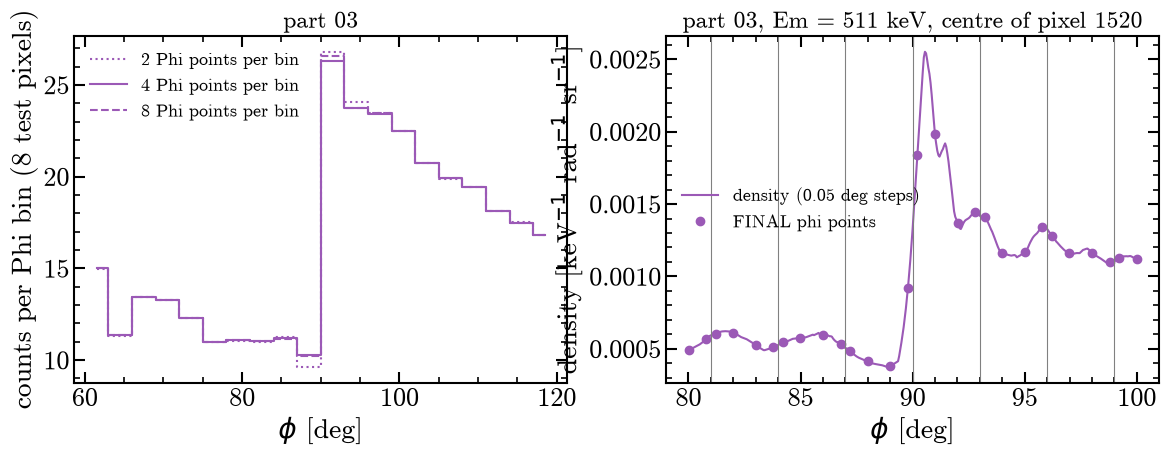

In [ ]:
t3 = templates[3]
phi_centres = 0.5 * (PHI_EDGES_DEG[:-1] + PHI_EDGES_DEG[1:])
in_range = (phi_centres > 60) & (phi_centres < 120)

# Test pixel with the most part-03 counts (from the Em test, 8 points) and its centre [rad]
pix3 = PIXELS[np.argmax(N_em[3, 8])]
colat_c, chi_c = hp.pix2ang(NSIDE, pix3, nest=(SCHEME == "nested"))

# FINAL phi points: set by a cheap compute (1 pixel, k = 0); phi_nodes_rad holds them afterwards
t3.compute(AXES, [pix3], subpixel_level=0, **FINAL)
phi_nodes = np.rad2deg(t3.phi_nodes_rad)
phi_nodes = phi_nodes[(phi_nodes > 80) & (phi_nodes < 100)]

# Raw NF density at (Em = 511 keV, phi, chi, psi): the same call the template makes, time ignored (version 3)
def density_at(phi_deg):
    const = lambda x: torch.full((len(phi_deg),), x, dtype=torch.float64)
    return t3._density_model.evaluate_density(torch.zeros(len(phi_deg)), const(511.0),
                                              torch.from_numpy(np.deg2rad(phi_deg)), const(chi_c), const(colat_c)).numpy()
phi_fine = np.linspace(80, 100, 401)                      # 0.05 deg steps

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for n_phi, ls in zip(N_PHI_VALUES, (":", "-", "--")):
    ax1.step(phi_centres[in_range], N_phi[3, n_phi][in_range], where="mid", ls=ls, color=COLORS["nf"],
             label=f"{n_phi} Phi points per bin")
ax1.set(xlabel=r"$\phi$ [deg]", ylabel="counts per Phi bin (8 test pixels)", title="part 03")
ax1.legend()

ax2.plot(phi_fine, density_at(phi_fine), color=COLORS["nf"], label="density (0.05 deg steps)")
ax2.plot(phi_nodes, density_at(phi_nodes), "o", color=COLORS["nf"], label="FINAL phi points")
for e in PHI_EDGES_DEG[(PHI_EDGES_DEG >= 80) & (PHI_EDGES_DEG <= 100)]:
    ax2.axvline(e, color=COLORS["ref"], lw=0.8)           # 3 deg bin edges
ax2.set(xlabel=r"$\phi$ [deg]", ylabel=r"density [keV$^{-1}$ rad$^{-1}$ sr$^{-1}$]",
        title=f"part 03, Em = 511 keV, centre of pixel {pix3}")
ax2.legend()
plt.show()

### 6.2 Extra breaks around φ = 90°

Same test as Section 6, with the bin 87–90° split at 89.5° (start of the rise) and the bin 90–93° split at 90.5, 91, 91.5, 92° (as 15–18° is split at 15.5–17°). All four parts: extra breaks only add φ points, so for smooth parts the result should not change beyond the quadrature error. ~2 min.

In [ ]:
# Phi breaks: FINAL (15.5-17 deg) plus splits at 89.5 deg (start of the rise) and in the bin 90-93 deg (the peak)
PHI_BREAKS_90 = FINAL["phi_breaks_deg"] + [89.5,90.5, 91.0, 91.5, 92.0]

N_phi90 = {}   # (part, n_phi) -> counts per Phi bin, shape (60,)
for part, t in templates.items():
    for n_phi in N_PHI_VALUES:
        P = t.compute(
            AXES, 
            PIXELS, 
            subpixel_level=1,
            n_phi_per_bin=n_phi,
            phi_breaks_deg=PHI_BREAKS_90, 
            **em_final)
        N_phi90[part, n_phi] = t.model_counts * P[0].sum(axis=1)

b90 = np.searchsorted(PHI_EDGES_DEG, 90.0)    # index of the bin 90-93 deg
for part in PARTS:
    ref, fin = N_phi90[part, 8], N_phi90[part, 4]
    ok = ref > 0.1
    rel = np.where(ok, fin / np.where(ok, ref, 1) - 1, 0)    # 4 vs 8 per Phi bin, with the new breaks
    b = np.argmax(np.abs(rel))
    old = N_phi[part, 4][b90] / N_phi[part, 8][b90] - 1      # same bin, FINAL breaks (Section 6)
    print(f"part {part:02d}: total 4 vs 8 {fin.sum() / ref.sum() - 1:+.3%} | bin 90-93: {rel[b90]:+.3%} (was {old:+.3%}) | "
          f"worst bin {PHI_EDGES_DEG[b]:3.0f}-{PHI_EDGES_DEG[b + 1]:3.0f} deg: {rel[b]:+.3%} ({fin[b]:.2f} vs {ref[b]:.2f} counts)")

Binning or settings changed: results of 11 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.


part 01: total 4 vs 8 -0.000% | bin 90-93: -0.002% (was +0.127%) | worst bin 171-174 deg: -0.755% (0.47 vs 0.48 counts)
part 02: total 4 vs 8 +0.005% | bin 90-93: -0.002% (was -0.150%) | worst bin 177-180 deg: -2.214% (0.22 vs 0.23 counts)
part 03: total 4 vs 8 +0.028% | bin 90-93: +0.012% (was -1.004%) | worst bin 177-180 deg: -0.617% (0.26 vs 0.26 counts)
part 04: total 4 vs 8 +0.092% | bin 90-93: +0.019% (was -1.288%) | worst bin  12- 15 deg: -3.069% (0.21 vs 0.22 counts)


## 7. Sky convergence (sub-pixel level k)

Test pixels plus pixels near the Earth horizon (colatitude 102–117°), at k = 1, 2, 3. Em and Phi at FINAL with the breaks of Section 6.2. FINAL uses k = 2. ~18 min.

In [ ]:
# Section 7. Sky convergence: test pixels + pixels near the Earth horizon, k = 1, 2, 3 (~22 min, five parts)
HORIZON_COLAT_DEG = np.array([102, 107, 117])           # 112 deg is already a test pixel (2096)
horizon = hp.ang2pix(NSIDE, np.deg2rad(HORIZON_COLAT_DEG), np.full(len(HORIZON_COLAT_DEG), np.pi / 2),
                     nest=(SCHEME == "nested"))
PIXELS_K = np.unique(np.concatenate([PIXELS, horizon]))
colat_k = np.rad2deg(hp.pix2ang(NSIDE, PIXELS_K, nest=(SCHEME == "nested"))[0])   # centre colatitude [deg]

K_VALUES = (1, 2, 3)
quad = dict(
    n_em_per_bin=FINAL["n_em_per_bin"], 
    em_breaks_kev=FINAL["em_breaks_kev"],
    n_phi_per_bin=FINAL["n_phi_per_bin"], 
    phi_breaks_deg=PHI_BREAKS_90
    )   # Phi breaks of Section 6.2

N_k = {}   # (part, k) -> counts per pixel (summed over Em and Phi), shape (11,)
for part, t in templates.items():
    for k in K_VALUES:
        P = t.compute(AXES, PIXELS_K, subpixel_level=k, **quad)
        N_k[part, k] = t.model_counts * P.sum(axis=(0, 1))

# Per part: total change k = 2 vs 3, and the pixel that changes most
for part in PARTS:
    rel = N_k[part, 2] / N_k[part, 3] - 1
    i = np.argmax(np.abs(rel))
    print(f"part {part:02d}: total k=2 vs 3 {N_k[part, 2].sum() / N_k[part, 3].sum() - 1:+.3%} | "
          f"worst pixel {PIXELS_K[i]} (colat {colat_k[i]:.0f} deg): {rel[i]:+.3%} "
          f"({N_k[part, 2][i]:.1f} vs {N_k[part, 3][i]:.1f} counts)")

Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.
Binning or settings changed: results of 8 computed pixel(s) discarded.


part 01: total k=2 vs 3 +0.022% | worst pixel 1520 (colat 90 deg): +0.406% (57.2 vs 57.0 counts)
part 02: total k=2 vs 3 -0.007% | worst pixel 1520 (colat 90 deg): +0.455% (129.9 vs 129.3 counts)
part 03: total k=2 vs 3 +0.011% | worst pixel 1520 (colat 90 deg): +0.874% (154.2 vs 152.9 counts)
part 04: total k=2 vs 3 +0.049% | worst pixel 1520 (colat 90 deg): +0.446% (85.0 vs 84.6 counts)


## 8. Polar pixel: default refinement vs one level finer

Pixel 0 (touches the north pole and χ = 0). Default (yaml `template:`): level 5, level 7 within 1° of the pole. Finer: level 6, level 8 within 1°. Cheap Em/Phi rule `QUAD` (2 Em points per half, 1 per Phi bin), as in notebook 09: the test isolates the sky integral. Part 01 is the control (validated in notebook 09). ~20 min.

In [ ]:
# Cheap Em/Phi rule of notebook 09: the comparison below only changes the sky points
QUAD = dict(n_em_per_bin=2, n_phi_per_bin=1, em_breaks_kev=[511.0], phi_breaks_deg=[])
POLAR_PIXEL = 0
FINER = {**settings["template"], "polar_subpixel_level": 6, "pole_subpixel_level": 8}   # one level finer at the pole

N_pole = {}   # (part, "default" / "finer") -> counts in pixel 0 (summed over Em and Phi)
for part, t in templates.items():
    t_finer = NFBinnedTemplate(MODEL_PATHS[part], **FINER)      # same model, finer polar refinement
    for name, tt in (("default", t), ("finer", t_finer)):
        P = tt.compute(AXES, [POLAR_PIXEL], subpixel_level=K_FINAL, **QUAD)   # level of pixel 0 set by the polar settings
        N_pole[part, name] = tt.model_counts * P.sum()
    print(f"part {part:02d}: pixel {POLAR_PIXEL} default {N_pole[part, 'default']:8.2f} | finer {N_pole[part, 'finer']:8.2f} | "
          f"default vs finer o{N_pole[part, 'default'] / N_pole[part, 'finer'] - 1:+.3%}")

part 01: pixel 0 default    66.30 | finer    66.47 | default vs finer -0.247%
part 02: pixel 0 default   103.34 | finer   103.31 | default vs finer +0.033%


Binning or settings changed: results of 11 computed pixel(s) discarded.


part 03: pixel 0 default    98.46 | finer    98.73 | default vs finer -0.267%


Binning or settings changed: results of 11 computed pixel(s) discarded.


part 04: pixel 0 default    62.11 | finer    62.29 | default vs finer -0.291%
